# B0 → B3 · 01. Dữ liệu mặt thật (LFW) và khẩu trang/kính giả

**Đồ án CV nâng cao · 20/11/2026**

Bước 7 cho thấy fine-tune trên ảnh tổng hợp (DigiFace) làm model kém trên ảnh người thật. Chuỗi cải tiến mới dựa trên bài báo của Anwar & Raychowdhury (2020), *Masked Face Recognition for Secure Authentication* (arXiv:2008.11104): dùng FaceNet, đeo khẩu trang giả lên **ảnh mặt thật** bằng công cụ MaskTheFace, rồi train trên ảnh đó. Bài báo cũng là nơi công bố bộ MFR2 mà nhóm dùng để test.

| | Thay đổi so với bước trước | Cơ sở |
|---|---|---|
| **B0** | FaceNet (InceptionResnetV1, VGGFace2) pretrained, ngưỡng chọn trên ảnh thật rõ mặt | Baseline của bài báo; FaceNet (Schroff 2015) |
| **B1** | **Đổi trọng số:** fine-tune nhẹ trên ảnh mặt thật đeo khẩu trang/kính giả | Cách làm của bài báo |
| **B2** | **Đổi ngưỡng và cách so khớp:** gallery thêm template đeo khẩu trang/kính giả, ngưỡng chọn trên ảnh thật có che | Bước 7: ngưỡng phải chọn đúng miền ảnh |
| **B3** | **Thêm model song song:** ghép điểm FaceNet (B2) với ArcFace | ArcFace (Deng 2019), InsightFace buffalo_l |

Notebook này chuẩn bị dữ liệu: LFW (Labeled Faces in the Wild, Huang 2007) làm ảnh mặt thật để train B1 và để chọn ngưỡng, sau khi loại những người trùng ROF/MFR2. ROF và MFR2 vẫn **chỉ để test**, đúng quyết định P3.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import os, sys, json, hashlib, time, gc, math, platform, inspect, warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code
import torch


def find_root():
    options = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(), *Path.cwd().parents]
    for p in options:
        if (p / 'ban_giao_nhom/cai_tien_B0_B3/cai_tien.py').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt CV_PROJECT_ROOT')


ROOT = find_root()
HERE = ROOT / 'ban_giao_nhom/cai_tien_B0_B3'
sys.path.insert(0, str(HERE)); sys.path.insert(0, str(ROOT / 'ban_giao_nhom/huan_luyen'))
import cai_tien
from cai_tien import FaceAligner, ArcFace, add_occlusion, facenet_embed, templates, best_match
from tai_model import load_encoder
LFW_DIR = ROOT / 'data/external/lfw/images'
ARCFACE_PATH = ROOT / 'data/external/arcface/w600k_r50.onnx'
SPLIT_DIR = HERE / 'outputs_01_du_lieu'
SEED = 20261120
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
START = time.perf_counter()


def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            h.update(b)
    return h.hexdigest()


def digest(x):
    return hashlib.sha256(json.dumps(x, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


def seed_of(*parts):
    return int(hashlib.sha256('|'.join(map(str, parts)).encode()).hexdigest()[:16], 16)


def vn(x, d=1):
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def pct(x, d=1):
    return vn(100 * x, d) + '%'


plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': .6})
COLORS = {'B0': '#8a8984', 'B1': '#2a78d6', 'B2': '#1baf7a', 'B3': '#eb6834'}

OUT = HERE / 'outputs_01_du_lieu'; TAB, FIG, CACHE = OUT / 'tables', OUT / 'figures', OUT / 'cache'
for p in [OUT, TAB, FIG, CACHE]:
    p.mkdir(parents=True, exist_ok=True)


def save(d, name):
    d.to_csv(TAB / (name + '.csv'), index=False, encoding='utf-8-sig', float_format='%.17g'); return d


def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG / (name + '.' + ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)

## 1. Kiểm kê LFW

LFW tải từ bản sao trên Hugging Face (`logasja/lfw`, file parquet 188 MB) vì hai nguồn chính thức (figshare, UMass) không tải được ngày 20/11/2026. Số ảnh và số người phải khớp bộ gốc: 13.233 ảnh, 5.749 người. Ảnh 250×250, người cần nhận nằm giữa ảnh.

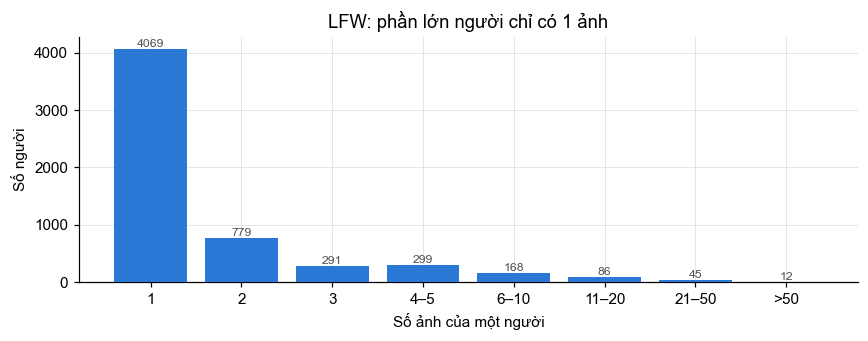

**13.233 ảnh, 5.749 người**; 610 người có từ 4 ảnh trở lên.

In [2]:
files = sorted(LFW_DIR.glob('*/*.jpg'))
with ThreadPoolExecutor(max_workers=6) as pool:
    hashes = list(pool.map(sha, files))
L = pd.DataFrame({'image_id': ['LFW_' + f.stem for f in files], 'identity': [f.parent.name for f in files],
                  'path': [f.relative_to(ROOT).as_posix() for f in files], 'sha256': hashes})
assert len(L) == 13233 and L.identity.nunique() == 5749, 'Không khớp số liệu LFW gốc'
counts = L.groupby('identity').size()
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = [1, 2, 3, 4, 6, 11, 21, 51, 600]
labels = ['1', '2', '3', '4–5', '6–10', '11–20', '21–50', '>50']
vals = pd.cut(counts, bins=bins, right=False, labels=labels).value_counts().reindex(labels)
ax.bar(labels, vals.values, color='#2a78d6', zorder=3); ax.bar_label(ax.containers[0], fontsize=8, color='#52514e')
ax.set(xlabel='Số ảnh của một người', ylabel='Số người', title='LFW: phần lớn người chỉ có 1 ảnh'); fig.tight_layout(); finish(fig, '01_lfw_images_per_person')
display(Markdown(f'**{vn(len(L), 0)} ảnh, {vn(L.identity.nunique(), 0)} người**; {vn((counts >= 4).sum(), 0)} người có từ 4 ảnh trở lên.'))

## 2. Loại người trùng với ROF và MFR2

LFW, ROF và MFR2 đều là ảnh người nổi tiếng nên có thể trùng người. Ai trùng tên (bỏ dấu cách, gạch dưới, chữ hoa) với một người trong ROF hoặc MFR2 bị loại khỏi mọi vai trò ở LFW, để model không được học hay chọn ngưỡng trên chính người sẽ test.

In [3]:
norm = lambda s: ''.join(ch for ch in s.lower() if ch.isalnum())
PROT = ROOT / 'ban_giao_nhom/protocol/notebook_outputs/tables'
ext = pd.read_csv(PROT / '07_external_image_roles_draft.csv', dtype=str, keep_default_na=False, usecols=['source', 'identity'])
test_names = {norm(x) for x in ext.identity}
L['norm'] = L.identity.map(norm)
overlap = sorted(set(L.loc[L.norm.isin(test_names), 'identity']))
removed = save(L[L.identity.isin(overlap)].groupby('identity').size().rename('ảnh').reset_index(), '01_removed_overlap_with_ROF_MFR2')
L = L[~L.identity.isin(overlap)].reset_index(drop=True)
display(removed.sort_values('ảnh', ascending=False).head(15))
display(Markdown(f'Loại **{len(overlap)} người** ({vn(removed["ảnh"].sum(), 0)} ảnh) trùng ROF/MFR2. Còn {vn(len(L), 0)} ảnh, {vn(L.identity.nunique(), 0)} người.'))

,identity,ảnh
56,Serena_Williams,52
3,Arnold_Schwarzenegger,42
47,Nicole_Kidman,19
5,Bill_Gates,17
39,Meryl_Streep,15
44,Nancy_Pelosi,15
54,Roger_Federer,14
0,Adrien_Brody,12
18,Harrison_Ford,12
29,Keanu_Reeves,12


Loại **62 người** (386 ảnh) trùng ROF/MFR2. Còn 12.847 ảnh, 5.687 người.

## 3. Tìm mặt và mốc mặt

MTCNN với cấu hình của bước 4/7. Ảnh LFW thường có người khác ở nền, nên khi thấy nhiều mặt thì chọn mặt gần tâm ảnh nhất (người cần nhận luôn ở giữa). Không thấy mặt thì dùng nguyên ảnh với mốc mặt chuẩn. Quy tắc này dùng chung cho LFW, ROF, MFR2 và app demo.

In [4]:
display(Code(inspect.getsource(FaceAligner.detect), language='python'))
cache = CACHE / 'lfw_detections.npz'
if cache.exists():
    with np.load(cache, allow_pickle=False) as z:
        assert z['image_id'].tolist() == L.image_id.tolist()
        BOX, LM, STATUS, NF = z['box'], z['lm'], z['status'], z['n_faces']
else:
    aligner = FaceAligner(device=DEVICE)
    dets = [aligner.detect(Image.open(ROOT / p).convert('RGB')) for p in L.path]
    BOX = np.stack([d['box'] for d in dets]); LM = np.stack([d['landmarks'] for d in dets])
    STATUS = np.array([d['status'] for d in dets], dtype='U'); NF = np.array([d['n_faces'] for d in dets])
    np.savez(cache, image_id=L.image_id.to_numpy(dtype='U'), box=BOX, lm=LM, status=STATUS, n_faces=NF)
L['status'] = STATUS
display(L.status.value_counts().rename('ảnh').to_frame())

@torch.inference_mode()
    def detect(self, image):
        """PIL RGB -> {status, box, landmarks (5×2, tọa độ ảnh), n_faces}.

        status: 'one_face' (thấy đúng 1 mặt), 'center_face' (nhiều mặt, chọn mặt gần tâm ảnh nhất),
        'fallback' (không thấy mặt: dùng nguyên ảnh, mốc mặt chuẩn).
        """
        w, h = image.size
        boxes, probs, points = self.mtcnn.detect(image, landmarks=True)
        if boxes is None or len(boxes) == 0:
            return {'status': 'fallback', 'box': np.array([0, 0, w, h], np.float32),
                    'landmarks': ARCFACE_TEMPLATE * np.array([w / 112, h / 112], np.float32), 'n_faces': 0}
        boxes = np.asarray(boxes, dtype=np.float32); points = np.asarray(points, dtype=np.float32)
        centers = (boxes[:, :2] + boxes[:, 2:]) / 2
        i = int(np.argmin(((centers - [w / 2, h / 2]) ** 2).sum(axis=1)))
        return {'status': 'one_face' if len(boxes) == 1 else 'center_face', 'box': boxes[i],
                'landmarks': points[i], 'n_faces': len(boxes)}

,ảnh
status,
one_face,10742
center_face,2105


## 4. Chia train / dev theo người

- **Train B1:** 70% số người có ít nhất 4 ảnh, tối đa 40 ảnh mỗi người (George W. Bush có 530 ảnh, không để một người chiếm phần lớn).
- **Dev người quen:** 30% còn lại. Mỗi người 2 ảnh làm gallery, tối đa 8 ảnh làm query.
- **Dev người lạ:** 600 người chỉ có 1–3 ảnh (không bao giờ vào gallery), mỗi người 1 ảnh.

Mỗi query dev có ba biến thể: rõ mặt, đeo khẩu trang giả, đeo kính giả (kiểu che chọn theo seed của ảnh). Dev dùng để chọn epoch cho B1 và chọn ngưỡng/trọng số ghép cho B0–B3; ROF/MFR2 không tham gia.

In [5]:
order = lambda xs, ctx: sorted(xs, key=lambda x: seed_of(SEED, ctx, x))
counts = L.groupby('identity').size()
multi = order(counts[counts >= 4].index, 'multi')
n_dev = round(0.3 * len(multi))
dev_known, train_ids = set(multi[:n_dev]), set(multi[n_dev:])
few = order(counts[counts <= 3].index, 'few')[:600]
role = {}
for ident, g in L.groupby('identity'):
    ids = order(g.image_id, 'img')
    if ident in train_ids:
        role.update({x: 'train' for x in ids[:40]})
    elif ident in dev_known:
        role.update({x: 'dev_gallery' for x in ids[:2]}); role.update({x: 'dev_known_query' for x in ids[2:10]})
    elif ident in few:
        role[ids[0]] = 'dev_unknown_query'
L['role'] = L.image_id.map(role).fillna('unused')
SPLIT = L[L.role.ne('unused')].reset_index(drop=True)
kinds = ['clean', 'mask', 'sunglasses']
SPLIT['occlusion_seed'] = [str(seed_of(SEED, 'occ', x)) for x in SPLIT.image_id]
summary = SPLIT.groupby('role').agg(ảnh=('image_id', 'size'), người=('identity', 'nunique')).reset_index()
assert not set(SPLIT[SPLIT.role.eq('train')].identity) & set(SPLIT[SPLIT.role.ne('train')].identity)
assert not set(SPLIT[SPLIT.role.eq('dev_unknown_query')].identity) & set(SPLIT[SPLIT.role.eq('dev_gallery')].identity)
cols = ['image_id', 'identity', 'path', 'sha256', 'role', 'status', 'occlusion_seed']
SPLIT[cols].to_csv(OUT / 'lfw_split.csv', index=False, encoding='utf-8-sig')
idx = L.set_index('image_id').index.get_indexer(SPLIT.image_id)
np.savez(OUT / 'lfw_split_detections.npz', image_id=SPLIT.image_id.to_numpy(dtype='U'), box=BOX[idx], lm=LM[idx], status=STATUS[idx])
save(summary, '02_split_summary'); display(summary)

,role,ảnh,người
0,dev_gallery,348,174
1,dev_known_query,767,174
2,dev_unknown_query,600,600
3,train,3734,406


## 5. Khẩu trang và kính râm giả

Vẽ theo 5 mốc mặt, trong hệ tọa độ gắn với đường nối hai mắt nên xoay theo mặt nghiêng. Khẩu trang có 7 kiểu (y tế xanh/trắng/xanh lá, vải đen/xám/họa tiết, N95), phủ từ sống mũi xuống cằm; kính râm 3 kiểu. Đây là phiên bản đơn giản của MaskTheFace: MaskTheFace dán ảnh mẫu khẩu trang theo 68 mốc của dlib, còn ở đây vẽ đa giác theo 5 mốc của MTCNN để không phải cài dlib.

def add_mask(image, landmarks, style=None, rng=None):
    """Vẽ khẩu trang giả theo 5 mốc mặt. image: PIL hoặc uint8 RGB -> uint8 RGB cùng kích thước."""
    rng = rng if rng is not None else np.random.default_rng(0)
    base = Image.fromarray(np.asarray(image, dtype=np.uint8)).convert('RGBA')
    style = style or str(rng.choice(list(MASK_STYLES)))
    color = MASK_STYLES[style]
    to_image, e, nose_b, mouth_b = _face_frame(landmarks)
    top = nose_b * 0.38
    chin = mouth_b + max(0.68, (mouth_b - nose_b) * 1.45)
    outline = [(0, top - 0.06), (0.45, top - 0.01), (0.88, top + 0.12), (1.12, nose_b + 0.12), (1.08, mouth_b + 0.06),
               (0.9, mouth_b + 0.4), (0.5, chin - 0.06), (0, chin), (-0.5, chin - 0.06), (-0.9, mouth_b + 0.4),
               (-1.08, mouth_b + 0.06), (-1.12, nose_b + 0.12), (-0.88, top + 0.12), (-0.45, top - 0.01)]
    layer = Image.new('RGBA', base.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(layer)
    draw.polygon(to_image(outline), fill=color + (255,))
    line_w = max(1, int(round(e * 0.035)))
    darker = tuple(int(c * 0.78) for c in color) + (255,)
    if style.startswith('surgical'):
        for b in [top + 0.28 * (chin - top), top + 0.45 * (chin - top), top + 0.62 * (chin - top)]:
            draw.line(to_image([(-1.0, b), (1.0, b)]), fill=darker, width=line_w)
    elif style == 'n95_white':
        draw.line(to_image([(0, top - 0.03), (0, chin - 0.02)]), fill=darker, width=line_w)
    elif style == 'cloth_pattern':
        stripe = tuple(min(255, int(c * 1.35) + 30) for c in color) + (255,)
        for k, b in enumerate(np.linspace(top + 0.1, chin - 0.1, 7)):
            if k % 2 == 0:
                draw.line(to_image([(-1.05, b), (1.05, b)]), fill=stripe, width=line_w * 2)
        draw.polygon(to_image(outline), outline=darker)
    loop = (225, 225, 225, 255) if sum(color) < 300 else darker
    for side in (-1, 1):
        draw.line(to_image([(side * 1.1, nose_b + 0.05), (side * 1.22, top - 0.25)]), fill=loop, width=line_w)
        draw.line(to_image([(side * 0.98, mouth_b + 0.3), (side * 1.22, mouth_b + 0.42)]), fill=loop, width=line_w)
    alpha = layer.getchannel('A')
    layer = _shade(layer, rng)
    layer.putalpha(alpha.filter(ImageFilter.GaussianBlur(radius=max(0.5, e * 0.012))))
    return np.asarray(Image.alpha_composite(base, layer).convert('RGB'), dtype=np.uint8)

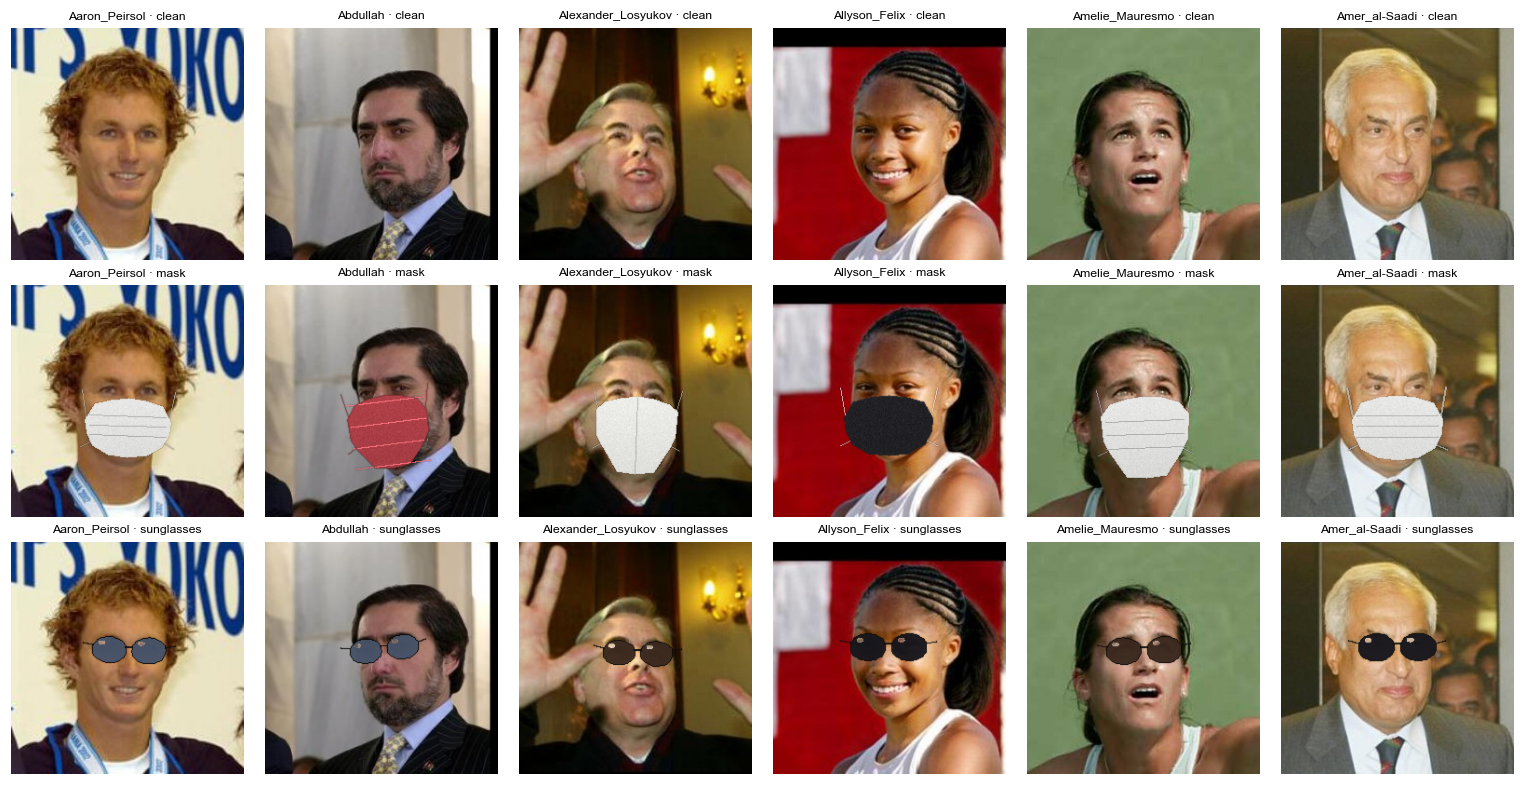

In [6]:
display(Code(inspect.getsource(cai_tien.add_mask), language='python'))
sample = SPLIT[SPLIT.role.eq('dev_gallery')].drop_duplicates('identity').head(6)
lm_by = dict(zip(SPLIT.image_id, np.load(OUT / 'lfw_split_detections.npz')['lm']))
fig, axes = plt.subplots(3, 6, figsize=(14, 7.2))
for j, r in enumerate(sample.itertuples()):
    im = Image.open(ROOT / r.path).convert('RGB')
    for i, kind in enumerate(kinds):
        axes[i, j].imshow(add_occlusion(im, lm_by[r.image_id], kind, np.random.default_rng(seed_of(SEED, kind, r.image_id))))
        axes[i, j].set_title(f'{r.identity[:18]} · {kind}', fontsize=8)
for ax in axes.flat:
    ax.axis('off')
fig.tight_layout(); finish(fig, '02_synthetic_occlusions')
json.dump({'checks': 'PASS', 'lfw_images': 13233, 'removed_overlap_identities': len(overlap), 'split': summary.to_dict('records'),
           'detections': L.status.value_counts().to_dict(), 'seed': SEED, 'executed_at_utc': datetime.now(timezone.utc).isoformat(),
           'elapsed_seconds': time.perf_counter() - START}, open(OUT / 'execution_summary.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)